In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from dlfs_autograd.model import SequentialModel
from dlfs_autograd.loss import MSE_Loss
from dlfs_autograd.optimizer import Optimizer_Adam
from dlfs_autograd.layers import DenseLayer, RecurrentLayer
from dlfs_autograd.modules import RNN

In [2]:
def convert_data_to_sequence(X, y, sequence_length, predict_sequence=False):
    X_new = []
    y_new = []

    if predict_sequence:
        for i in range(len(X) - sequence_length):
            X_new.append(X[i:i+sequence_length, :])
            y_new.append(y[i:i+sequence_length])
    else:
        for i in range(len(X) - sequence_length):
            X_new.append(X[i:i+sequence_length, :])
            y_new.append(y[i+sequence_length])

    X_new, y_new = np.array(X_new), np.array(y_new)

    return X_new, y_new

def create_sine_data(start, stop, n_samples):
    X = np.linspace(start, stop, n_samples)
    y = np.sin(X)
    return X, y

X, y = create_sine_data(-20, 20, 500)

# Sine data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X.reshape(-1, 1), 
    y.reshape(-1, 1), 
    test_size=0.2,
    shuffle=False
)

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')

X_train: (400, 1), y_train: (400, 1)
X_test: (100, 1), y_test: (100, 1)


In [4]:
sequence_len = 5

X_train_seq, y_train_seq = convert_data_to_sequence(X_train, y_train, sequence_len)
X_test_seq, y_test_seq = convert_data_to_sequence(X_test, y_test, sequence_len)

print(f'X_train: {X_train_seq.shape}, y_train: {y_train_seq.shape}')
print(f'X_test: {X_test_seq.shape}, y_test: {y_test_seq.shape}')

X_train: (395, 5, 1), y_train: (395, 1)
X_test: (95, 5, 1), y_test: (95, 1)


In [5]:
#np.random.seed(0)

layers = [
    RNN(1, 16),
    DenseLayer(16, 1)
]

lr = 1e-2

model = SequentialModel(layers=layers, loss_function=MSE_Loss(), optimizer=Optimizer_Adam(learning_rate=lr))
model.train(X_train_seq, y_train_seq, epochs=500, batch_size=None, print_every=100)

===== EPOCH : 0 ===== LOSS : 0.30373960733413696 =====
===== EPOCH : 100 ===== LOSS : 0.12762103974819183 =====
===== EPOCH : 200 ===== LOSS : 0.06226472556591034 =====
===== EPOCH : 300 ===== LOSS : 0.03215932846069336 =====
===== EPOCH : 400 ===== LOSS : 0.002271505305543542 =====
===== EPOCH : 500 ===== LOSS : 0.002071087947115302 =====


Sequence loss: 0.0017367546679452062


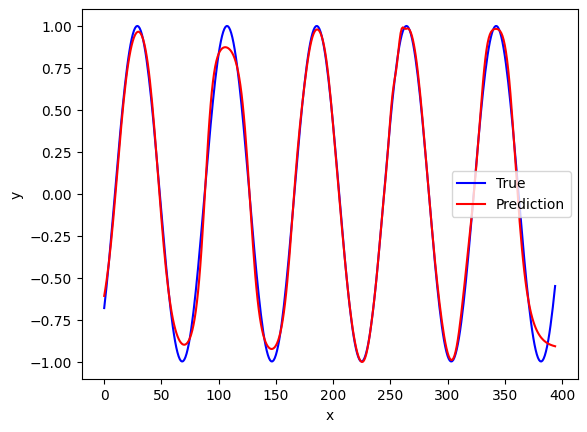

In [6]:
x_range = [x for x in range(len(X_train_seq))]

x = X_train_seq
y_true = y_train_seq

y_pred = model.predict(x)
loss = model.loss_function.calculate(y_pred, y_true)

print(f'Sequence loss: {loss.data}')

plt.plot(x_range, y_true, color='blue', label="True")
plt.plot(x_range, y_pred, color="red", label="Prediction")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# Weather data

In [7]:
data = pd.read_csv('../data/clean_weather.csv', names=['date', 'tmax', 'tmin', 'rain', 'tmax_tomorrow'], header=0)
print(data.shape)
data.head()

(13509, 5)


,date,tmax,tmin,rain,tmax_tomorrow
0,1970-01-01,60.0,35.0,0.0,52.0
1,1970-01-02,52.0,39.0,0.0,52.0
2,1970-01-03,52.0,35.0,0.0,53.0
3,1970-01-04,53.0,36.0,0.0,52.0
4,1970-01-05,52.0,35.0,0.0,50.0


In [8]:
data = data.dropna()
print(data.shape)

(13203, 5)


In [9]:
FEATURES = ['tmax', 'tmin', 'rain']
TARGET = 'tmax_tomorrow'

X = data[FEATURES].to_numpy()
y = data[TARGET].to_numpy()

print(f'X: {X.shape}')
print(f'y: {y.shape}')

X: (13203, 3)
y: (13203,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train.reshape(-1, 1)).reshape(-1)
y_test = scaler_y.transform(y_test.reshape(-1, 1)).reshape(-1)

print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')

X_train: (10562, 3), y_train: (10562,)
X_test: (2641, 3), y_test: (2641,)


# One to one

In [11]:
seq_len = 1

X_train_one, y_train_one = convert_data_to_sequence(X_train, y_train.reshape(-1, 1), seq_len)
X_test_one, y_test_one = convert_data_to_sequence(X_test, y_test.reshape(-1, 1), seq_len)

print(f'X_train_one: {X_train_one.shape}, y_train_one: {y_train_one.shape}')
print(f'X_test_one: {X_test_one.shape}, y_test_one: {y_test_one.shape}')

X_train_one: (10561, 1, 3), y_train_one: (10561, 1)
X_test_one: (2640, 1, 3), y_test_one: (2640, 1)


In [12]:
#np.random.seed(0)

layers = [RNN(3, 32, n_layers=2),
          DenseLayer(32, 1)]
lr = 1e-2

model = SequentialModel(layers=layers, loss_function=MSE_Loss(), optimizer=Optimizer_Adam(learning_rate=lr))
model.train(X_train_one, y_train_one, epochs=5000, batch_size=3000, print_every=500)

===== EPOCH : 0 ===== LOSS : 0.5048551559448242 =====
===== EPOCH : 500 ===== LOSS : 0.24856892228126526 =====
===== EPOCH : 1000 ===== LOSS : 0.24011994898319244 =====
===== EPOCH : 1500 ===== LOSS : 0.23521606624126434 =====
===== EPOCH : 2000 ===== LOSS : 0.25189632177352905 =====
===== EPOCH : 2500 ===== LOSS : 0.2299213856458664 =====
===== EPOCH : 3000 ===== LOSS : 0.230825275182724 =====
===== EPOCH : 3500 ===== LOSS : 0.23523405194282532 =====
===== EPOCH : 4000 ===== LOSS : 0.23733174800872803 =====
===== EPOCH : 4500 ===== LOSS : 0.2353975474834442 =====
===== EPOCH : 5000 ===== LOSS : 0.22423583269119263 =====


In [13]:
y_pred = model.predict(X_test_one)
y_true = y_test_one
loss = model.loss_function.calculate(y_pred, y_true)
print(f'Test loss: {loss.data}')

Test loss: 0.25587522983551025


Test sequence loss: 11.055257797241211


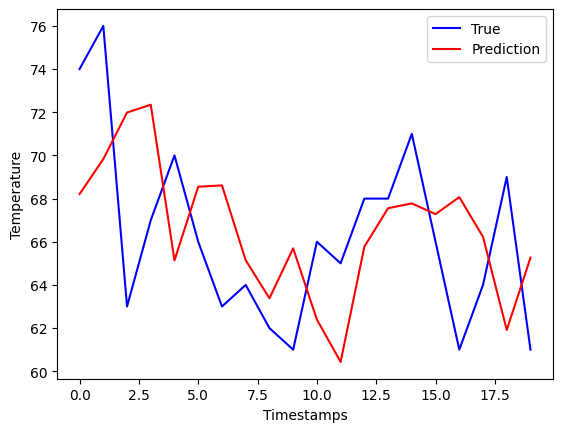

In [14]:
from random import randint

n_samples = 20
x_range = np.array([x for x in range(n_samples)])

rand_idx = randint(0, len(X_test_one) - n_samples)
x = X_test_one[rand_idx:rand_idx+n_samples]
y_pred = model.predict(x)
y_true = y_test_one[rand_idx:rand_idx+n_samples]

y_pred = scaler_y.inverse_transform(y_pred).reshape(-1)
y_true = scaler_y.inverse_transform(y_true.reshape(-1, 1)).reshape(-1)

loss = model.loss_function.calculate(y_pred, y_true)

print(f'Test sequence loss: {loss.data}')

plt.plot(x_range, y_true, color='blue', label="True")
plt.plot(x_range, y_pred, color="red", label="Prediction")
plt.xlabel('Timestamps')
plt.ylabel('Temperature')
plt.legend()
plt.show()

# Many to one

In [15]:
seq_len = 10

X_train_seq, y_train_seq = convert_data_to_sequence(X_train, y_train.reshape(-1, 1), seq_len)
X_test_seq, y_test_seq = convert_data_to_sequence(X_test, y_test.reshape(-1, 1), seq_len)

print(f'X_train_seq: {X_train_seq.shape}, y_train_seq: {y_train_seq.shape}')
print(f'X_test_seq: {X_test_seq.shape}, y_test_seq: {y_test_seq.shape}')

X_train_seq: (10552, 10, 3), y_train_seq: (10552, 1)
X_test_seq: (2631, 10, 3), y_test_seq: (2631, 1)


In [16]:
layers = [RNN(3, 64), 
          DenseLayer(64, 1)]

lr = 1e-3

model = SequentialModel(layers=layers, loss_function=MSE_Loss(), optimizer=Optimizer_Adam(learning_rate=lr))
model.train(X_train_seq, y_train_seq, epochs=500, batch_size=3000, print_every=100)

===== EPOCH : 0 ===== LOSS : 0.4331294894218445 =====
===== EPOCH : 100 ===== LOSS : 0.23206818103790283 =====
===== EPOCH : 200 ===== LOSS : 0.22427116334438324 =====
===== EPOCH : 300 ===== LOSS : 0.22919555008411407 =====
===== EPOCH : 400 ===== LOSS : 0.2211112678050995 =====
===== EPOCH : 500 ===== LOSS : 0.21893344819545746 =====


In [17]:
y_pred = model.predict(X_test_seq)
y_true = y_test_seq
loss = model.loss_function.calculate(y_pred, y_true)
print(f'Test loss: {loss.data}')

Test loss: 0.22984248399734497


Test sequence loss: 12.262825012207031


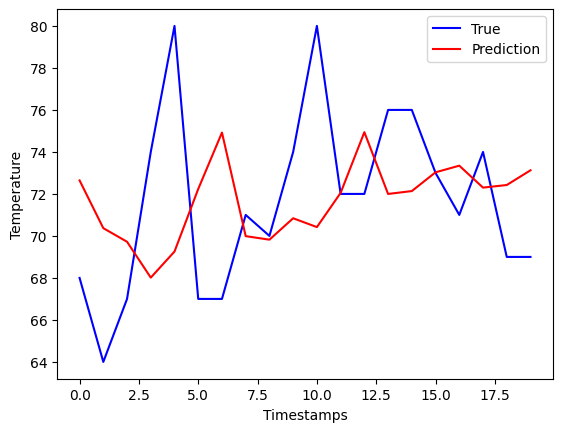

In [18]:
n_samples = 20
x_range = np.array([x for x in range(n_samples)])

rand_idx = randint(0, len(X_test_seq) - n_samples)
x = X_test_seq[rand_idx:rand_idx+n_samples]
y_pred = model.predict(x)
y_true = y_test_seq[rand_idx:rand_idx+n_samples]

y_pred = scaler_y.inverse_transform(y_pred).reshape(-1)
y_true = scaler_y.inverse_transform(y_true.reshape(-1, 1)).reshape(-1)

loss = model.loss_function.calculate(y_pred, y_true)

print(f'Test sequence loss: {loss.data}')

plt.plot(x_range, y_true, color='blue', label="True")
plt.plot(x_range, y_pred, color="red", label="Prediction")
plt.xlabel('Timestamps')
plt.ylabel('Temperature')
plt.legend()
plt.show()

# Many to many

In [19]:
seq_len = 7

X_train_seq, y_train_seq = convert_data_to_sequence(X_train, y_train.reshape(-1, 1), seq_len, predict_sequence=True)
X_test_seq, y_test_seq = convert_data_to_sequence(X_test, y_test.reshape(-1, 1), seq_len, predict_sequence=True)

print(f'X_train_seq: {X_train_seq.shape}, y_train_seq: {y_train_seq.shape}')
print(f'X_test_seq: {X_test_seq.shape}, y_test_seq: {y_test_seq.shape}')

X_train_seq: (10555, 7, 3), y_train_seq: (10555, 7, 1)
X_test_seq: (2634, 7, 3), y_test_seq: (2634, 7, 1)


In [20]:
layers = [RNN(3, 64, n_layers=2, predict_sequence=True), 
          DenseLayer(64, 1)]

lr = 1e-3

model = SequentialModel(layers=layers, loss_function=MSE_Loss(), optimizer=Optimizer_Adam(learning_rate=lr))
model.train(X_train_seq, y_train_seq, epochs=500, batch_size=4000, print_every=100)

===== EPOCH : 0 ===== LOSS : 0.5091105699539185 =====
===== EPOCH : 100 ===== LOSS : 0.1576012820005417 =====
===== EPOCH : 200 ===== LOSS : 0.15520308911800385 =====
===== EPOCH : 300 ===== LOSS : 0.15661922097206116 =====
===== EPOCH : 400 ===== LOSS : 0.15738336741924286 =====
===== EPOCH : 500 ===== LOSS : 0.1546364575624466 =====


In [21]:
y_pred = model.predict(X_test_seq)
y_true = y_test_seq
loss = model.loss_function.calculate(y_pred, y_true)
print(f'Test loss: {loss.data}')

Test loss: 0.15384218096733093


Sequence loss: 6.748727321624756


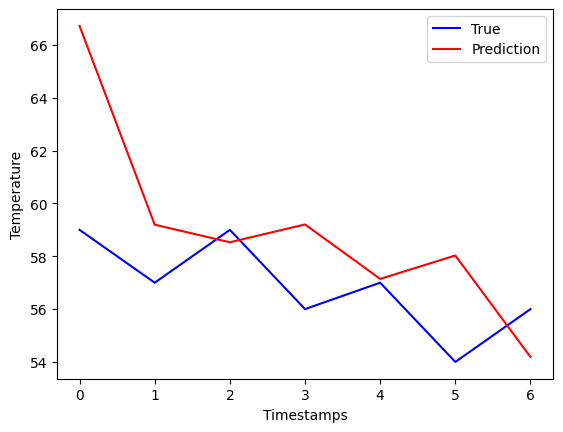

In [30]:
timestamps = 7
x = np.array([x for x in range(timestamps)])

rand_idx = randint(0, len(X_test_seq))
y_true = y_test_seq[rand_idx]
y_true = scaler_y.inverse_transform(y_true.reshape(-1, 1))

x_pred = X_test_seq[rand_idx].reshape(1, *X_test_seq[0].shape)
y_pred = model.predict(x_pred).flatten()
y_pred = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

loss = model.loss_function.calculate(y_pred, y_true)
print(f'Sequence loss: {loss.data}')

plt.plot(x, y_true, color='blue', label="True")
plt.plot(x, y_pred, color="red", label="Prediction")
plt.xlabel('Timestamps')
plt.ylabel('Temperature')
plt.legend()
plt.show()